In [1]:
import numpy as np

class Perceptron:
    def __init__(self, epochs=50, lr=0.1):
        self.epochs = epochs
        self.lr = lr
        self.W_ = []
        self.b_ = 0.0

    def fit(self, X, Y):
        self.W_ = np.zeros(shape=len(X[0]), dtype=float)

        for _ in range(self.epochs):
            for x, y in zip(X, Y):
                pred_y = self.predict(x)
                diff_y = y - pred_y
                self.W_ += self.lr * diff_y * x
                self.b_ += self.lr * diff_y

    def predict(self, x):
        return np.where((x.dot(self.W_.T) + self.b_) > 0, 1, 0)
    

In [2]:
from sklearn.datasets import load_iris
iris = load_iris()

X, y = iris.data, iris.target

target_indices = (y == 1) | (y == 0)
X = X[target_indices]
y = y[target_indices]

X = X[:, [2,3]]

In [3]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
def plot_decision_regions(X, y, classifier, resolution=0.02):
    # setup marker generator and color map
    markers = ('o', 's', '^', 'v', '<')
    colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    cmap = ListedColormap(colors[:len(np.unique(y))])
    
    # plot the decision surface
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    lab = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    lab = lab.reshape(xx1.shape)
    plt.contourf(xx1, xx2, lab, alpha=0.3, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())
    
    # plot class examples
    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y == cl, 0],
                    y=X[y == cl, 1],
                    alpha=0.8,
                    c=colors[idx],
                    marker=markers[idx],
                    label=f'Class {cl}',
                    edgecolor='black')

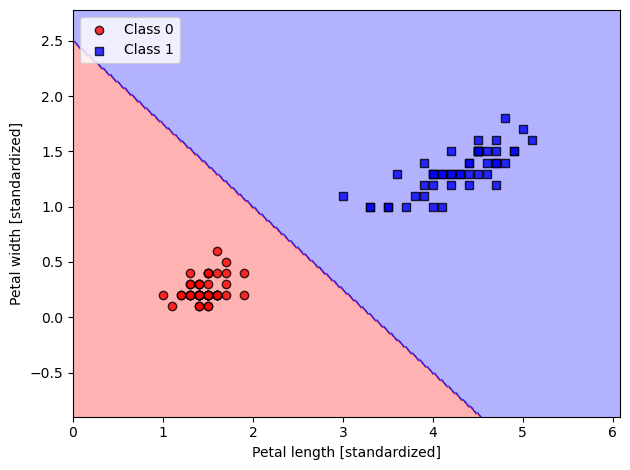

In [4]:
model = Perceptron()
model.fit(X, y)
plot_decision_regions(X, y, classifier=model)
plt.xlabel('Petal length [standardized]')
plt.ylabel('Petal width [standardized]')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()